### installations

In [ ]:
!pip install dwave-ocean-sdk
!pip install numpy pandas cvxpy yfinance matplotlib

In [ ]:
!pip install qiskit qiskit-aer qiskit-optimization seaborn 

### api

In [ ]:
"""
D-Wave Quantum Portfolio Optimization - Compact Implementation
"""

import numpy as np
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from dwave.system import LeapHybridCQMSampler
from dimod import ConstrainedQuadraticModel, Binary, quicksum

# ============================================================================
# DATA ACQUISITION
# ============================================================================

def get_stock_data(tickers, years=2):
    end = datetime.now()
    start = end - timedelta(days=years * 365)

    data = yf.download(tickers, start=start, end=end)

    if isinstance(data.columns, pd.MultiIndex):
        data = data['Close']
    else:
        data = data[['Close']]

    return data.dropna()


def calculate_returns(price_data):
    returns = price_data.pct_change().dropna()
    mean_returns = returns.mean()
    cov_matrix = returns.cov()
    return returns, mean_returns, cov_matrix


# ============================================================================
# QUANTUM OPTIMIZATION
# ============================================================================

def build_cqm(mean_returns, cov_matrix, max_assets, risk_coef):
    n = len(mean_returns)

    x = {i: Binary(f'x_{i}') for i in range(n)}

    cqm = ConstrainedQuadraticModel()

    objective = risk_coef * quicksum(
        cov_matrix.iloc[i, j] * x[i] * x[j]
        for i in range(n) for j in range(n)
    )

    objective -= quicksum(mean_returns.iloc[i] * x[i] for i in range(n))

    cqm.set_objective(objective)

    cqm.add_constraint(
        quicksum(x[i] for i in range(n)) == max_assets,
        label='cardinality'
    )

    return cqm, x


def solve_quantum(cqm):
    sampler = LeapHybridCQMSampler()
    sampleset = sampler.sample_cqm(cqm)

    feasible = sampleset.filter(lambda s: s.is_feasible)

    if len(feasible):
        best = feasible.first.sample
        energy = feasible.first.energy
        return best, energy

    return None, None


# ============================================================================
# WEIGHT ALLOCATION
# ============================================================================

def allocate_weights(selected_indices, mean_returns, cov_matrix):
    selected_returns = mean_returns.iloc[selected_indices]
    selected_cov = cov_matrix.iloc[selected_indices, selected_indices]

    n = len(selected_indices)

    def portfolio_variance(w):
        return w @ selected_cov.values @ w

    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    bounds = [(0, 1)] * n

    initial = np.ones(n) / n

    result = minimize(
        portfolio_variance,
        initial,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )

    return result.x


# ============================================================================
# PERFORMANCE METRICS
# ============================================================================

def calculate_metrics(weights, mean_returns, cov_matrix):
    port_return = weights @ mean_returns.values
    port_vol = np.sqrt(weights @ cov_matrix.values @ weights)

    sharpe = port_return / port_vol if port_vol > 0 else 0

    return {
        'return': port_return * 252,
        'volatility': port_vol * np.sqrt(252),
        'sharpe': sharpe * np.sqrt(252)
    }


# ============================================================================
# VISUALIZATION
# ============================================================================

def plot_results(portfolio_value, benchmark_value, selected_stocks, weights):

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    axes[0, 0].plot(portfolio_value.index, portfolio_value.values, label='Quantum Portfolio')
    axes[0, 0].plot(benchmark_value.index, benchmark_value.values, label='S&P 500')
    axes[0, 0].set_title('Portfolio Performance')
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    axes[0, 1].bar(selected_stocks, weights)
    axes[0, 1].set_title('Portfolio Weights')
    axes[0, 1].tick_params(axis='x', rotation=45)
    axes[0, 1].grid(True)

    returns = portfolio_value.pct_change().dropna()
    axes[1, 0].hist(returns, bins=50)
    axes[1, 0].set_title('Return Distribution')
    axes[1, 0].grid(True)

    cum_returns = (1 + returns).cumprod()
    axes[1, 1].plot(cum_returns.index, cum_returns.values)
    axes[1, 1].set_title('Cumulative Returns')
    axes[1, 1].grid(True)

    plt.tight_layout()
    plt.show()


# ============================================================================
# MAIN EXECUTION
# ============================================================================

def run_optimization(tickers, max_assets=6, risk_coef=0.5, years=2):

    print("Downloading data...")
    price_data = get_stock_data(tickers, years)

    print("Calculating returns...")
    returns, mean_returns, cov_matrix = calculate_returns(price_data)

    print("Building quantum model...")
    cqm, variables = build_cqm(mean_returns, cov_matrix, max_assets, risk_coef)

    print("Solving on D-Wave...")
    solution, energy = solve_quantum(cqm)

    if solution is None:
        print("No feasible solution found!")
        return None

    selected_idx = [i for i in range(len(tickers)) if solution[f'x_{i}'] == 1]
    selected_stocks = [tickers[i] for i in selected_idx]

    print("\nSelected Stocks:")
    print(selected_stocks)

    weights = allocate_weights(selected_idx, mean_returns, cov_matrix)

    print("\nWeights:")
    for s, w in zip(selected_stocks, weights):
        print(f"{s}: {w:.2%}")

    metrics = calculate_metrics(
        weights,
        mean_returns.iloc[selected_idx],
        cov_matrix.iloc[selected_idx, selected_idx]
    )

    print("\nPortfolio Metrics:")
    print(f"Expected Return: {metrics['return']:.2%}")
    print(f"Volatility: {metrics['volatility']:.2%}")
    print(f"Sharpe Ratio: {metrics['sharpe']:.2f}")

    selected_prices = price_data.iloc[:, selected_idx]
    portfolio_value = (selected_prices * weights).sum(axis=1)

    spy_data = yf.download(
        'SPY',
        start=price_data.index[0],
        end=price_data.index[-1]
    )['Close']

    plot_results(portfolio_value, spy_data, selected_stocks, weights)

    return {
        'stocks': selected_stocks,
        'weights': weights,
        'metrics': metrics,
        'energy': energy
    }


# ============================================================================
# RUN
# ============================================================================

if __name__ == "__main__":

    stocks = [
        'AAPL', 'MSFT', 'GOOGL', 'NVDA',
        'JPM', 'BAC', 'GS',
        'AMZN', 'TSLA', 'WMT'
    ]

    result = run_optimization(
        tickers=stocks,
        max_assets=6,
        risk_coef=0.5,
        years=2
    )


[                       0%                       ]

[*********************100%***********************]  10 of 10 completed


Calculating returns...
Building quantum model...
Solving on D-Wave...


ValueError: API token not defined

### no api (qaoa)

In [1]:
"""
IBM Quantum QAOA Portfolio Optimization - No API Key Required
Uses local Qiskit simulator for quantum optimization
"""

import numpy as np
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter
from qiskit_aer.primitives import Sampler

# ============================================================================
# DATA ACQUISITION
# ============================================================================

def get_stock_data(tickers, years=2):
    end = datetime.now()
    start = end - timedelta(days=years*365)

    data = yf.download(
        tickers,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )

    if isinstance(data.columns, pd.MultiIndex):
        prices = data['Close']
    else:
        prices = data[['Close']]

    return prices.dropna()

def calculate_returns(price_data):
    """Calculate returns and covariance"""
    returns = price_data.pct_change().dropna()
    mean_returns = returns.mean()
    cov_matrix = returns.cov()
    return returns, mean_returns, cov_matrix

# ============================================================================
# STEP R1: FORMULATE AS QUBO
# ============================================================================

def build_qubo(mean_returns, cov_matrix, max_assets, risk_coef, penalty=10):
    """
    Build QUBO matrix for portfolio optimization
    
    Minimize: risk_coef * x^T Cov x - returns^T x + penalty * (sum(x) - B)^2
    """
    n = len(mean_returns)
    Q = np.zeros((n, n))
    
    # Risk term: quadratic covariance
    Q += risk_coef * cov_matrix.values
    
    # Return term: linear (on diagonal for QUBO format)
    for i in range(n):
        Q[i, i] -= mean_returns.iloc[i]
    
    # Cardinality constraint penalty: (sum(x) - B)^2
    # Expands to: sum(x_i^2) + 2*sum(x_i*x_j) - 2*B*sum(x_i) + B^2
    for i in range(n):
        Q[i, i] += penalty * (1 - 2 * max_assets)
        for j in range(i + 1, n):
            Q[i, j] += penalty
            Q[j, i] += penalty
    
    return Q

# ============================================================================
# STEP R2: CONVERT TO ISING HAMILTONIAN
# ============================================================================

def qubo_to_ising(Q):
    """
    Convert QUBO to Ising Hamiltonian
    x ∈ {0,1} → s ∈ {-1,+1}
    Transformation: x = (s + 1) / 2
    """
    n = Q.shape[0]
    
    # Initialize Ising parameters
    h = np.zeros(n)  # Linear terms
    J = np.zeros((n, n))  # Quadratic terms
    offset = 0
    
    # Convert QUBO to Ising
    for i in range(n):
        h[i] = Q[i, i] / 2
        for j in range(n):
            h[i] += Q[i, j] / 4
            offset += Q[i, j] / 4
    
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = Q[i, j] / 4
    
    # Normalize for circuit stability
    max_val = max(np.max(np.abs(h)), np.max(np.abs(J)))
    if max_val > 0:
        h = h / max_val
        J = J / max_val
    
    return h, J, offset

# ============================================================================
# STEP R3: BUILD QAOA CIRCUIT
# ============================================================================

def build_qaoa_circuit(h, J, p=1):
    """
    Build QAOA circuit with p layers
    
    Args:
        h: Linear Ising coefficients
        J: Quadratic Ising coefficients
        p: Number of QAOA layers
    """
    n = len(h)
    qc = QuantumCircuit(n)
    
    # Parameters
    gamma = [Parameter(f'γ_{i}') for i in range(p)]
    beta = [Parameter(f'β_{i}') for i in range(p)]
    
    # Initial state: uniform superposition
    qc.h(range(n))
    
    # QAOA layers
    for layer in range(p):
        # Cost Hamiltonian: exp(-i * gamma * H_C)
        # Apply ZZ gates for coupling terms
        for i in range(n):
            for j in range(i + 1, n):
                if J[i, j] != 0:
                    qc.rzz(2 * gamma[layer] * J[i, j], i, j)
        
        # Apply Z gates for linear terms
        for i in range(n):
            if h[i] != 0:
                qc.rz(2 * gamma[layer] * h[i], i)
        
        # Mixer Hamiltonian: exp(-i * beta * H_M)
        for i in range(n):
            qc.rx(2 * beta[layer], i)
    
    # Measure all qubits
    qc.measure_all()
    
    return qc, gamma + beta

# ============================================================================
# STEP R4 & R5: RUN QAOA OPTIMIZATION
# ============================================================================

def evaluate_energy(counts, h, J):
    """Calculate expected energy from measurement counts"""
    energy = 0
    total_shots = sum(counts.values())
    
    for bitstring, count in counts.items():
        # Convert bitstring to spin configuration
        s = np.array([1 if bit == '0' else -1 for bit in bitstring])
        
        # Calculate energy for this configuration
        E = np.dot(h, s) + sum(J[i, j] * s[i] * s[j] 
                               for i in range(len(s)) 
                               for j in range(i + 1, len(s)))
        
        energy += E * (count / total_shots)
    
    return energy

def run_qaoa(h, J, p=1, max_iter=50):
    """
    Run QAOA optimization using local simulator
    
    Args:
        h: Linear Ising coefficients
        J: Quadratic Ising coefficients
        p: Number of QAOA layers
        max_iter: Maximum optimization iterations
    """
    print(f"Running QAOA with p={p} layers...")
    
    # Build circuit
    qc, params = build_qaoa_circuit(h, J, p)
    
    # Use local simulator (no API key needed)
    backend = AerSimulator()
    
    # Objective function
    def objective(theta):
        bound_circuit = qc.assign_parameters(dict(zip(params, theta)), inplace=False)
        job = backend.run(bound_circuit, shots=1024)
        counts = job.result().get_counts()
        return evaluate_energy(counts, h, J)
    
    # Initial parameters
    initial_theta = np.random.uniform(0, 2*np.pi, len(params))
    
    # Optimize
    result = minimize(objective, initial_theta, method='COBYLA', 
                     options={'maxiter': max_iter})
    
    print(f"Optimization converged: {result.success}")
    print(f"Final energy: {result.fun:.4f}")
    
    # Get final measurement
    final_circuit = qc.assign_parameters(dict(zip(params, result.x)), inplace=False)

    job = backend.run(final_circuit, shots=2048)
    counts = job.result().get_counts()
    
    return counts, result.fun

# ============================================================================
# STEP R6 & R7: DECODE SOLUTION
# ============================================================================

def decode_solution(counts, max_assets, tickers):
    """
    Extract most probable solution and verify constraints
    
    Returns selected stocks
    """
    # Get most frequent bitstring
    best_bitstring = max(counts, key=counts.get)
    
    # Convert to binary selection
    selected = [i for i, bit in enumerate(best_bitstring) if bit == '0']
    
    print(f"\nRaw solution: {len(selected)} assets selected")
    
    # Step R7: Verify cardinality constraint
    if len(selected) != max_assets:
        print(f"Constraint violated! Applying post-processing...")
        # Get all candidates sorted by probability
        candidates = []
        for bitstring, count in counts.items():
            selection = [i for i, bit in enumerate(bitstring) if bit == '0']
            if abs(len(selection) - max_assets) <= 2:  # Close to target
                candidates.append((selection, count))
        
        # Pick best valid solution
        for selection, count in sorted(candidates, key=lambda x: x[1], reverse=True):
            if len(selection) == max_assets:
                selected = selection
                print(f"Found valid solution with {count} counts")
                break
        else:
            # Force to exact count
            if len(selected) > max_assets:
                selected = selected[:max_assets]
            else:
                # Add random stocks to meet constraint
                remaining = [i for i in range(len(tickers)) if i not in selected]
                selected.extend(remaining[:max_assets - len(selected)])
    
    selected_stocks = [tickers[i] for i in selected]
    print(f"Final selection: {selected_stocks}")
    
    return selected, selected_stocks

# ============================================================================
# STEP R8: CLASSICAL WEIGHT ALLOCATION
# ============================================================================

def allocate_weights(selected_indices, mean_returns, cov_matrix, method='sharpe'):
    """
    Classical optimization for portfolio weights
    
    Args:
        method: 'sharpe' (maximize Sharpe ratio) or 'min_var' (minimum variance)
    """
    selected_returns = mean_returns.iloc[selected_indices]
    selected_cov = cov_matrix.iloc[selected_indices, selected_indices]
    n = len(selected_indices)
    
    if method == 'sharpe':
        # Maximize Sharpe ratio (return/risk)
        def negative_sharpe(w):
            port_return = w @ selected_returns
            port_vol = np.sqrt(w @ selected_cov @ w)
            if port_vol == 0:
                return 1e10
            return -port_return / port_vol  # Negative because we minimize
    
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0, 1) for _ in range(n)]
        initial = np.ones(n) / n
        
        result = minimize(negative_sharpe, initial, method='SLSQP', 
                         bounds=bounds, constraints=constraints)
    
    elif method == 'min_var':
        # Minimum variance
        def portfolio_variance(w):
            return w @ selected_cov @ w
        
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0, 1) for _ in range(n)]
        initial = np.ones(n) / n
        
        result = minimize(portfolio_variance, initial, method='SLSQP', 
                         bounds=bounds, constraints=constraints)
    
    else:
        raise ValueError("method must be 'sharpe' or 'min_var'")
    
    return result.x
# ============================================================================
# PERFORMANCE METRICS
# ============================================================================

def calculate_metrics(weights, mean_returns, cov_matrix):
    """Calculate portfolio performance metrics"""
    port_return = weights @ mean_returns
    port_vol = np.sqrt(weights @ cov_matrix @ weights)
    sharpe = port_return / port_vol if port_vol > 0 else 0
    
    return {
        'return': port_return * 252,
        'volatility': port_vol * np.sqrt(252),
        'sharpe': sharpe * np.sqrt(252)
    }

def plot_results(portfolio_value, benchmark_value, selected_stocks, weights):
    """Generate performance plots"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    axes[0, 0].plot(portfolio_value.index, portfolio_value.values, label='QAOA Portfolio', linewidth=2)
    axes[0, 0].plot(benchmark_value.index, benchmark_value.values, label='S&P 500', linewidth=2, alpha=0.7)
    axes[0, 0].set_title('Portfolio Performance')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].bar(selected_stocks, weights)
    axes[0, 1].set_title('Portfolio Weights')
    axes[0, 1].tick_params(axis='x', rotation=45)
    axes[0, 1].grid(True, alpha=0.3)
    
    returns = portfolio_value.pct_change().dropna()
    axes[1, 0].hist(returns, bins=50, alpha=0.7, edgecolor='black')
    axes[1, 0].set_title('Return Distribution')
    axes[1, 0].grid(True, alpha=0.3)
    
    cum_returns = (1 + portfolio_value.pct_change()).cumprod()
    axes[1, 1].plot(cum_returns.index, cum_returns.values, linewidth=2)
    axes[1, 1].set_title('Cumulative Returns')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# ============================================================================
# MAIN EXECUTION
# ============================================================================

def run_qaoa_optimization(tickers, max_assets=6, risk_coef=0.5, years=2, qaoa_layers=1):
    """Run complete QAOA optimization pipeline"""
    
    print("="*70)
    print("IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)")
    print("="*70)
    
    print("\n[1/8] Downloading data...")
    price_data = get_stock_data(tickers, years)
    
    print("[2/8] Calculating returns and covariance...")
    returns, mean_returns, cov_matrix = calculate_returns(price_data)
    
    print("[3/8] Building QUBO...")
    Q = build_qubo(mean_returns, cov_matrix, max_assets, risk_coef)
    
    print("[4/8] Converting to Ising Hamiltonian...")
    h, J, offset = qubo_to_ising(Q)
    
    print("[5/8] Running QAOA optimization...")
    counts, energy = run_qaoa(h, J, p=qaoa_layers)
    
    print("[6/8] Decoding solution...")
    selected_idx, selected_stocks = decode_solution(counts, max_assets, tickers)
    
    print("[7/8] Allocating weights...")
    weights = allocate_weights(selected_idx, mean_returns, cov_matrix)
    
    print("\n" + "="*70)
    print("RESULTS")
    print("="*70)
    print("\nSelected Stocks & Weights:")
    for stock, weight in zip(selected_stocks, weights):
        print(f"  {stock}: {weight:.2%}")
    
    print("[8/8] Calculating metrics...")
    metrics = calculate_metrics(weights, mean_returns.iloc[selected_idx], 
                               cov_matrix.iloc[selected_idx, selected_idx])
    
    print(f"\nPortfolio Metrics:")
    print(f"  Expected Return: {metrics['return']:.2%}")
    print(f"  Volatility: {metrics['volatility']:.2%}")
    print(f"  Sharpe Ratio: {metrics['sharpe']:.2f}")
    
    # Backtest
    selected_prices = price_data.iloc[:, selected_idx]
    portfolio_value = (selected_prices @ weights).dropna()
    
    spy_data = yf.download(
        'SPY',
        start=price_data.index[0],
        end=price_data.index[-1],
        auto_adjust=True,
        progress=False
    )['Close']

    plot_results(portfolio_value, spy_data, selected_stocks, weights)
    
    return {
        'stocks': selected_stocks,
        'weights': weights,
        'metrics': metrics,
        'energy': energy
    }

# ============================================================================
# EXAMPLE USAGE
# ============================================================================
"""
if __name__ == "__main__":
    stocks = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'JPM', 
    'V', 'JNJ', 'WMT', 'PG', 'MA', 'HD', 'CVX', 'MRK', 'ABBV',
    'PEP', 'COST', 'AVGO', 'ADBE', 'CRM', 'NFLX', 'TMO', 'CSCO', 
    'ORCL', 'ACN', 'INTC'
]
    
    result = run_qaoa_optimization(
        tickers=stocks,
        max_assets=6,
        risk_coef=0.5,
        years=2,
        qaoa_layers=1  # Increase for better results (slower)
    )"""

'\nif __name__ == "__main__":\n    stocks = [\n    \'AAPL\', \'MSFT\', \'GOOGL\', \'AMZN\', \'NVDA\', \'META\', \'TSLA\', \'JPM\', \n    \'V\', \'JNJ\', \'WMT\', \'PG\', \'MA\', \'HD\', \'CVX\', \'MRK\', \'ABBV\',\n    \'PEP\', \'COST\', \'AVGO\', \'ADBE\', \'CRM\', \'NFLX\', \'TMO\', \'CSCO\', \n    \'ORCL\', \'ACN\', \'INTC\'\n]\n\n    result = run_qaoa_optimization(\n        tickers=stocks,\n        max_assets=6,\n        risk_coef=0.5,\n        years=2,\n        qaoa_layers=1  # Increase for better results (slower)\n    )'

In [3]:
stocks = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'JPM', 
    'V', 'JNJ', 'WMT', 'PG', 'MA', 'HD', 'CVX', 'MRK', 'ABBV',
    'PEP', 'COST', 'AVGO', 'ADBE', 'CRM', 'NFLX', 'TMO', 'CSCO', 
    'ORCL', 'ACN', 'INTC'
]

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=2 layers...
Optimization converged: True
Final energy: -23.7135
[6/8] Decoding solution...

Raw solution: 28 assets selected
Constraint violated! Applying post-processing...
Final selection: ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'JPM', 'V', 'JNJ', 'WMT', 'PG', 'MA', 'HD', 'CVX', 'MRK', 'ABBV', 'PEP', 'COST', 'AVGO']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  AAPL: 5.00%
  MSFT: 5.00%
  GOOGL: 5.00%
  AMZN: 5.00%
  NVDA: 5.00%
  META: 5.00%
  TSLA: 5.00%
  JPM: 5.00%
  V: 5.00%
  JNJ: 5.00%
  WMT: 5.00%
  PG: 5.00%
  MA: 5.00%
  HD: 5.00%
  CVX: 5.00%
  MRK: 5.00%
  ABBV: 5.00%
  PEP: 5.00%
  COST: 5.00%
  AVGO: 5.00%
[8/8] Calculating metrics...

Portfolio Metrics:
  Expected Return: 17.53%
  Volatility: 16

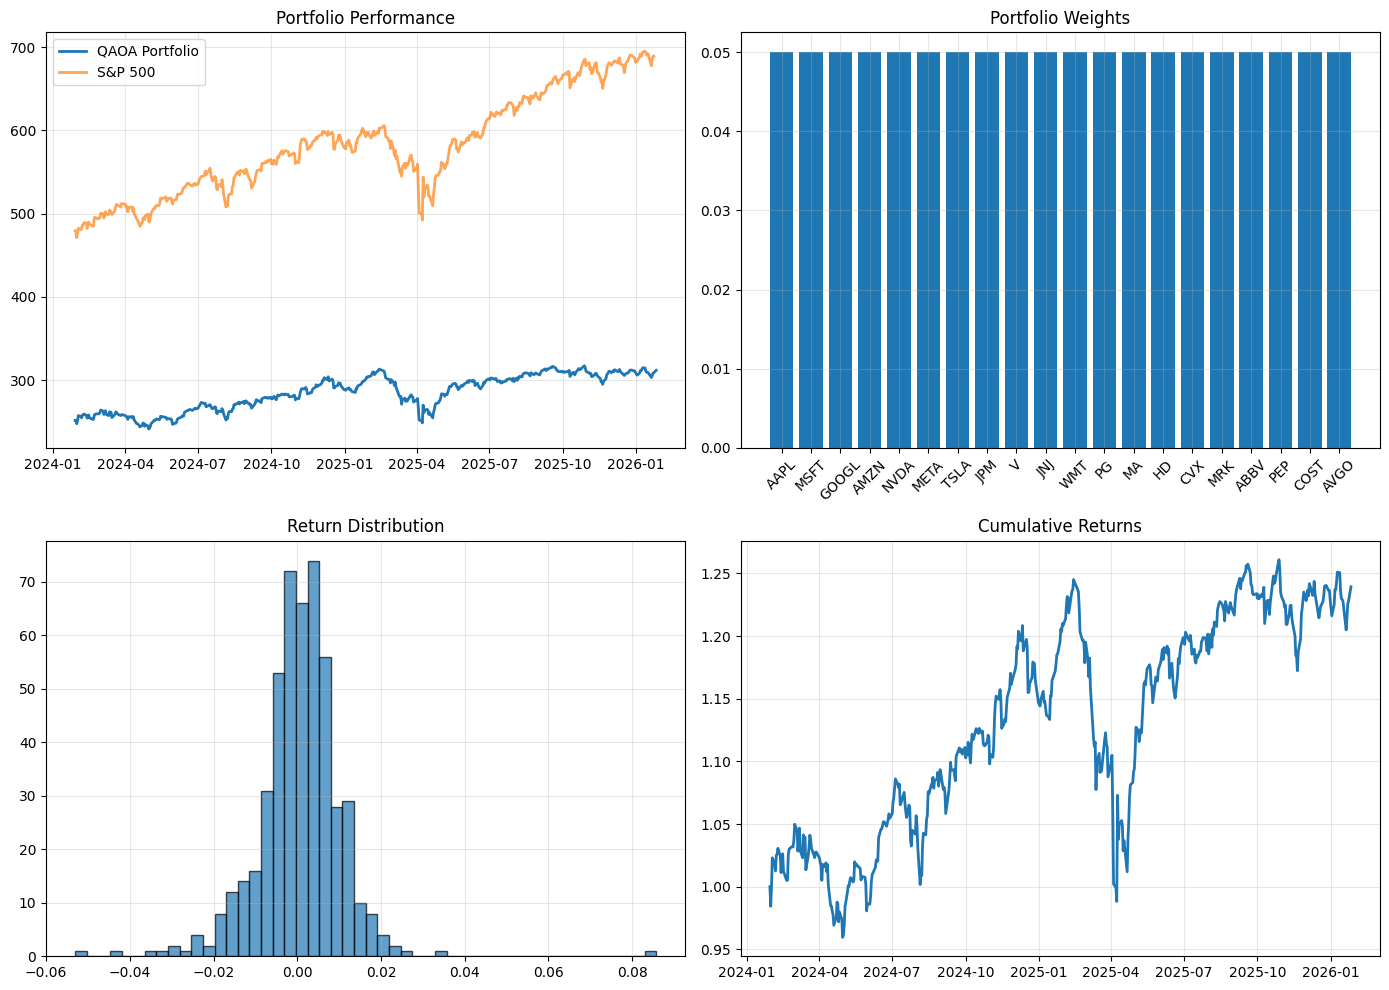

In [3]:
result = run_qaoa_optimization(
        tickers=stocks,
        max_assets=20,
        risk_coef=0.3,
        years=2,
        qaoa_layers=2  # Increase for better results (slower)
    )

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=2 layers...
Optimization converged: True
Final energy: -21.3686
[6/8] Decoding solution...

Raw solution: 28 assets selected
Constraint violated! Applying post-processing...
Found valid solution with 1 counts
Final selection: ['MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'JPM', 'V', 'JNJ', 'WMT', 'MA', 'HD', 'CVX', 'COST', 'CRM', 'NFLX', 'TMO', 'CSCO', 'ORCL', 'ACN', 'INTC']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  MSFT: 5.00%
  GOOGL: 5.00%
  AMZN: 5.00%
  NVDA: 5.00%
  META: 5.00%
  JPM: 5.00%
  V: 5.00%
  JNJ: 5.00%
  WMT: 5.00%
  MA: 5.00%
  HD: 5.00%
  CVX: 5.00%
  COST: 5.00%
  CRM: 5.00%
  NFLX: 5.00%
  TMO: 5.00%
  CSCO: 5.00%
  ORCL: 5.00%
  ACN: 5.00%
  INTC: 5.00%
[8/8] Calculating metrics...

Portfolio Metrics:
  Exp

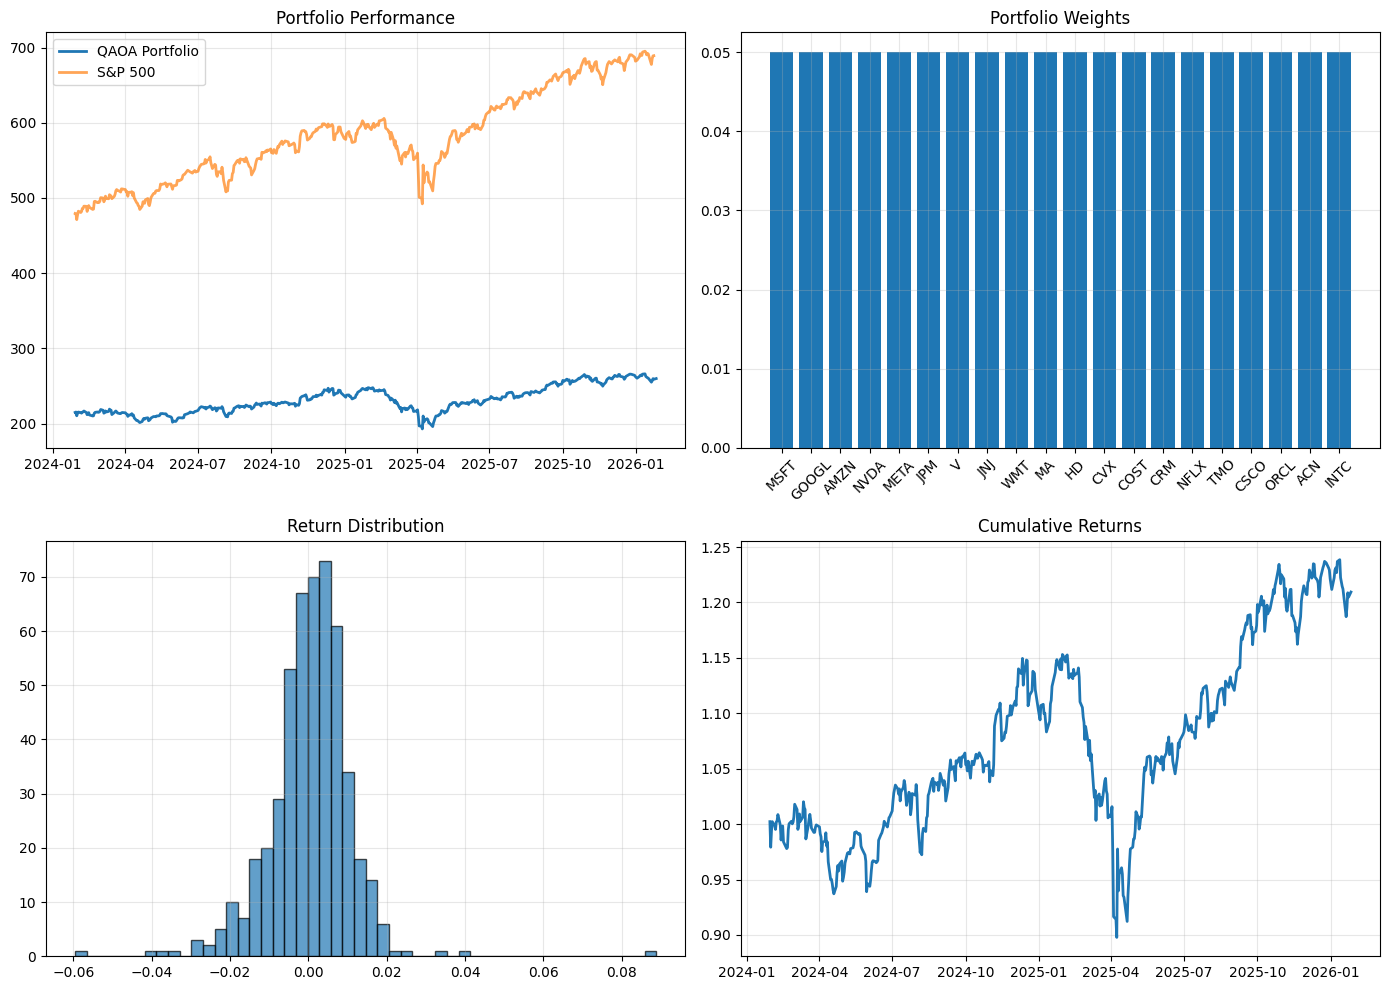

In [4]:
result2 = run_qaoa_optimization(
        tickers=stocks,
        max_assets=20,
        risk_coef=0.5,
        years=2,
        qaoa_layers=2  # Increase for better results (slower)
    )

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=2 layers...
Optimization converged: True
Final energy: -23.6891
[6/8] Decoding solution...

Raw solution: 28 assets selected
Constraint violated! Applying post-processing...
Final selection: ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'JPM', 'V', 'JNJ', 'WMT', 'PG', 'MA', 'HD', 'CVX', 'MRK', 'ABBV', 'PEP', 'COST', 'AVGO']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  AAPL: 5.00%
  MSFT: 5.00%
  GOOGL: 5.00%
  AMZN: 5.00%
  NVDA: 5.00%
  META: 5.00%
  TSLA: 5.00%
  JPM: 5.00%
  V: 5.00%
  JNJ: 5.00%
  WMT: 5.00%
  PG: 5.00%
  MA: 5.00%
  HD: 5.00%
  CVX: 5.00%
  MRK: 5.00%
  ABBV: 5.00%
  PEP: 5.00%
  COST: 5.00%
  AVGO: 5.00%
[8/8] Calculating metrics...

Portfolio Metrics:
  Expected Return: 17.44%
  Volatility: 16

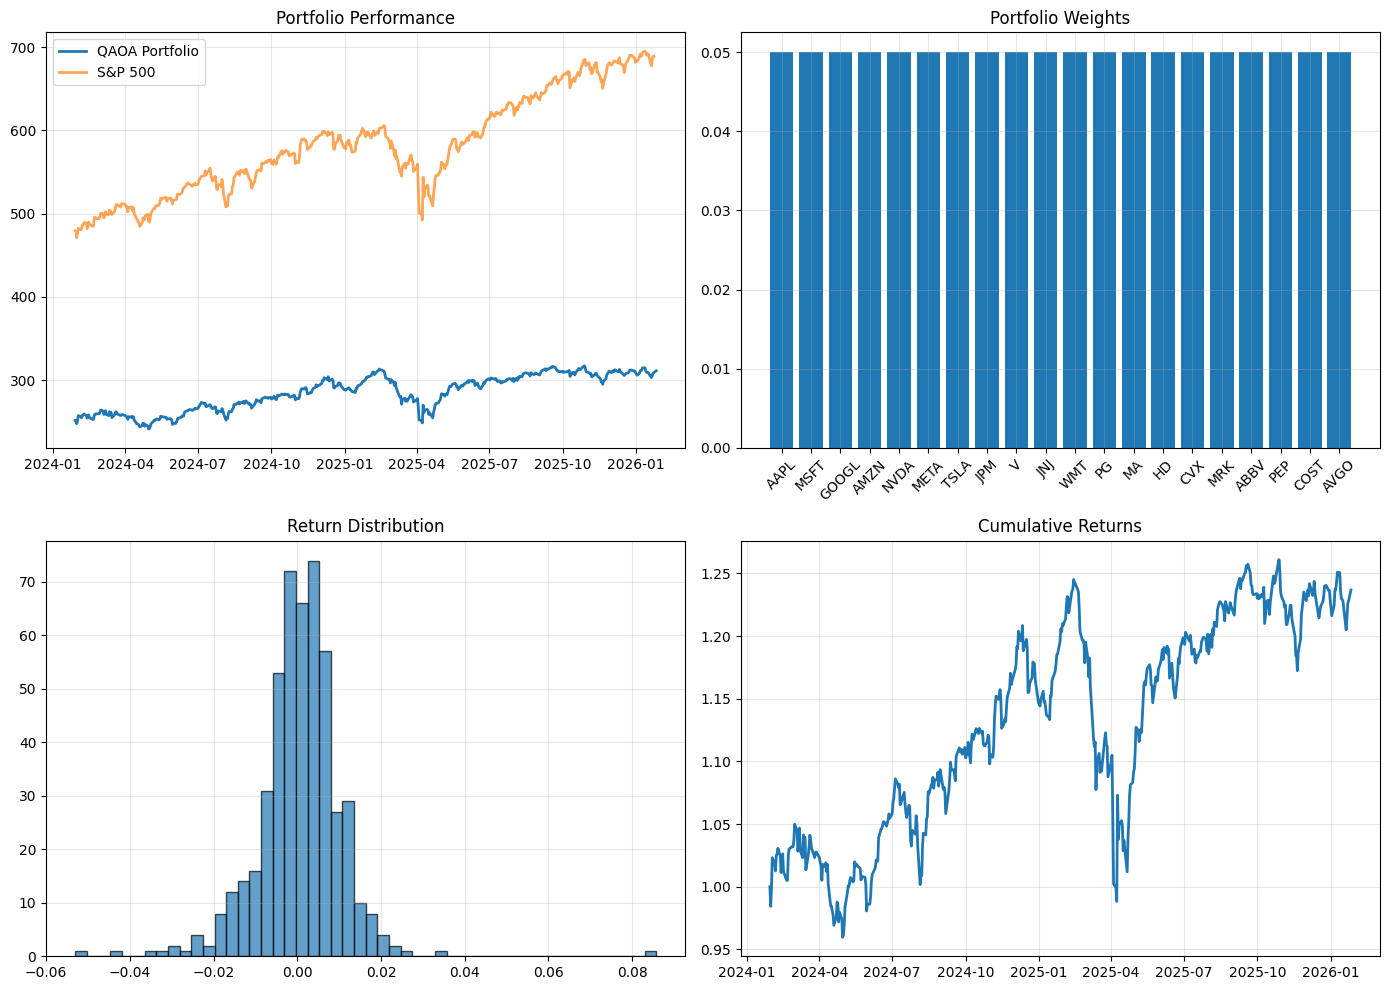

In [5]:
result3 = run_qaoa_optimization(
        tickers=stocks,
        max_assets=20,
        risk_coef=0.7,
        years=2,
        qaoa_layers=2  # Increase for better results (slower)
    )

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=2 layers...
Optimization converged: True
Final energy: -22.9243
[6/8] Decoding solution...

Raw solution: 28 assets selected
Constraint violated! Applying post-processing...
Found valid solution with 1 counts
Final selection: ['AAPL', 'MSFT', 'AMZN', 'NVDA', 'META', 'V', 'JNJ', 'MA', 'MRK', 'ABBV', 'PEP', 'COST', 'AVGO', 'ADBE', 'CRM', 'NFLX', 'CSCO', 'ORCL', 'ACN', 'INTC']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  AAPL: 5.00%
  MSFT: 5.00%
  AMZN: 5.00%
  NVDA: 5.00%
  META: 5.00%
  V: 5.00%
  JNJ: 5.00%
  MA: 5.00%
  MRK: 5.00%
  ABBV: 5.00%
  PEP: 5.00%
  COST: 5.00%
  AVGO: 5.00%
  ADBE: 5.00%
  CRM: 5.00%
  NFLX: 5.00%
  CSCO: 5.00%
  ORCL: 5.00%
  ACN: 5.00%
  INTC: 5.00%
[8/8] Calculating metrics...

Portfolio Metrics:

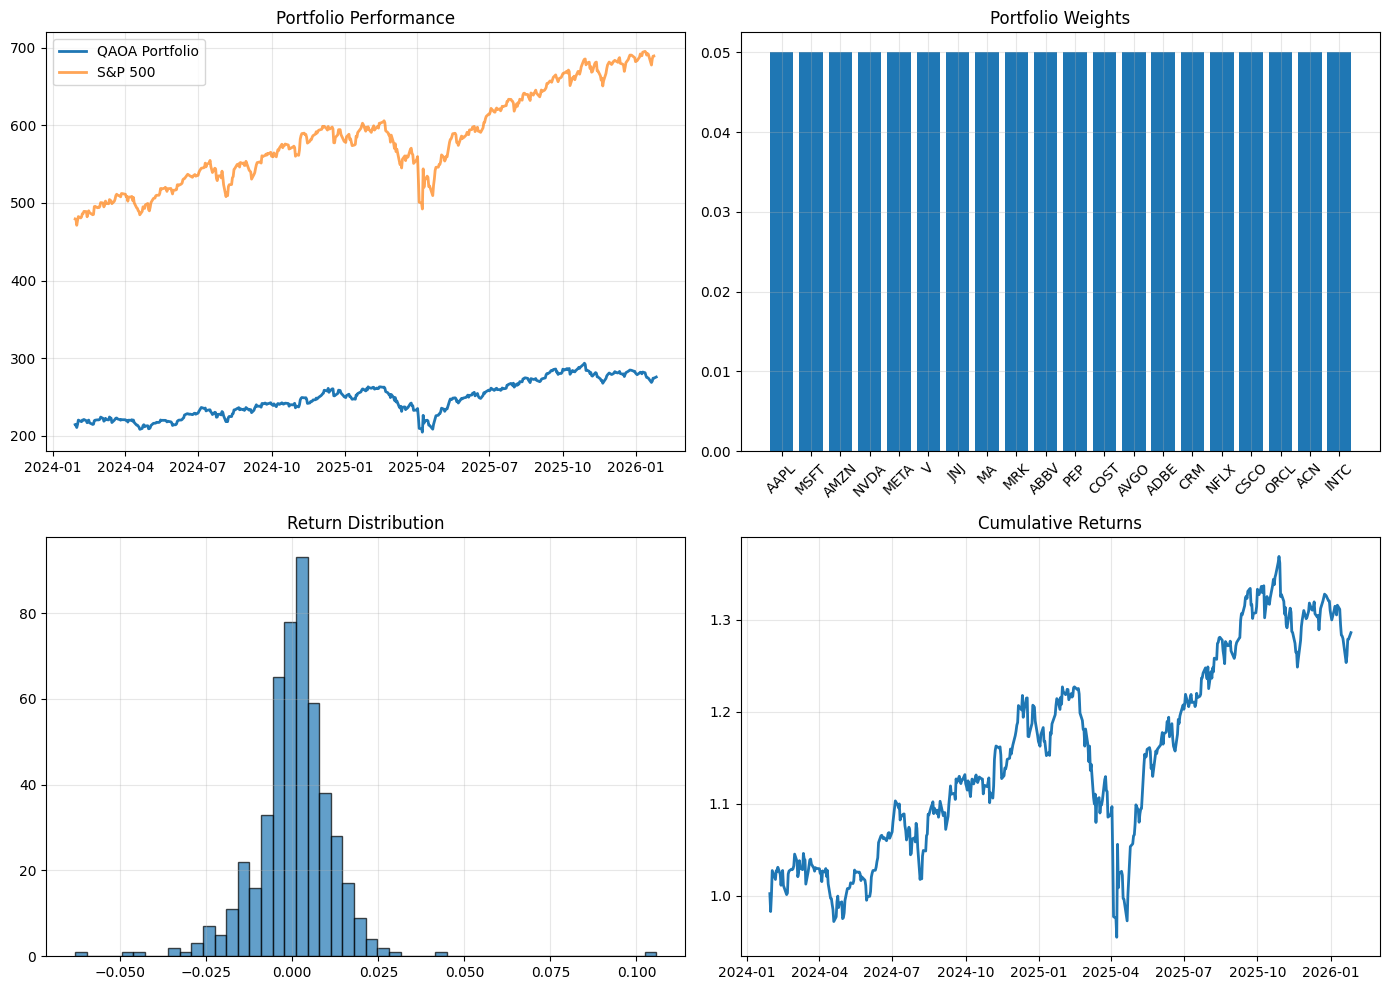

In [6]:
result4 = run_qaoa_optimization(
        tickers=stocks,
        max_assets=20,
        risk_coef=0.9,
        years=2,
        qaoa_layers=2  # Increase for better results (slower)
    )

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=1 layers...
Optimization converged: True
Final energy: -0.5231
[6/8] Decoding solution...

Raw solution: 12 assets selected
Constraint violated! Applying post-processing...
Found valid solution with 1 counts
Final selection: ['GOOGL', 'AMZN', 'JNJ', 'PEP', 'AVGO', 'NFLX']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  GOOGL: 16.67%
  AMZN: 16.67%
  JNJ: 16.67%
  PEP: 16.67%
  AVGO: 16.67%
  NFLX: 16.67%
[8/8] Calculating metrics...

Portfolio Metrics:
  Expected Return: -0.58%
  Volatility: 14.66%
  Sharpe Ratio: -0.04


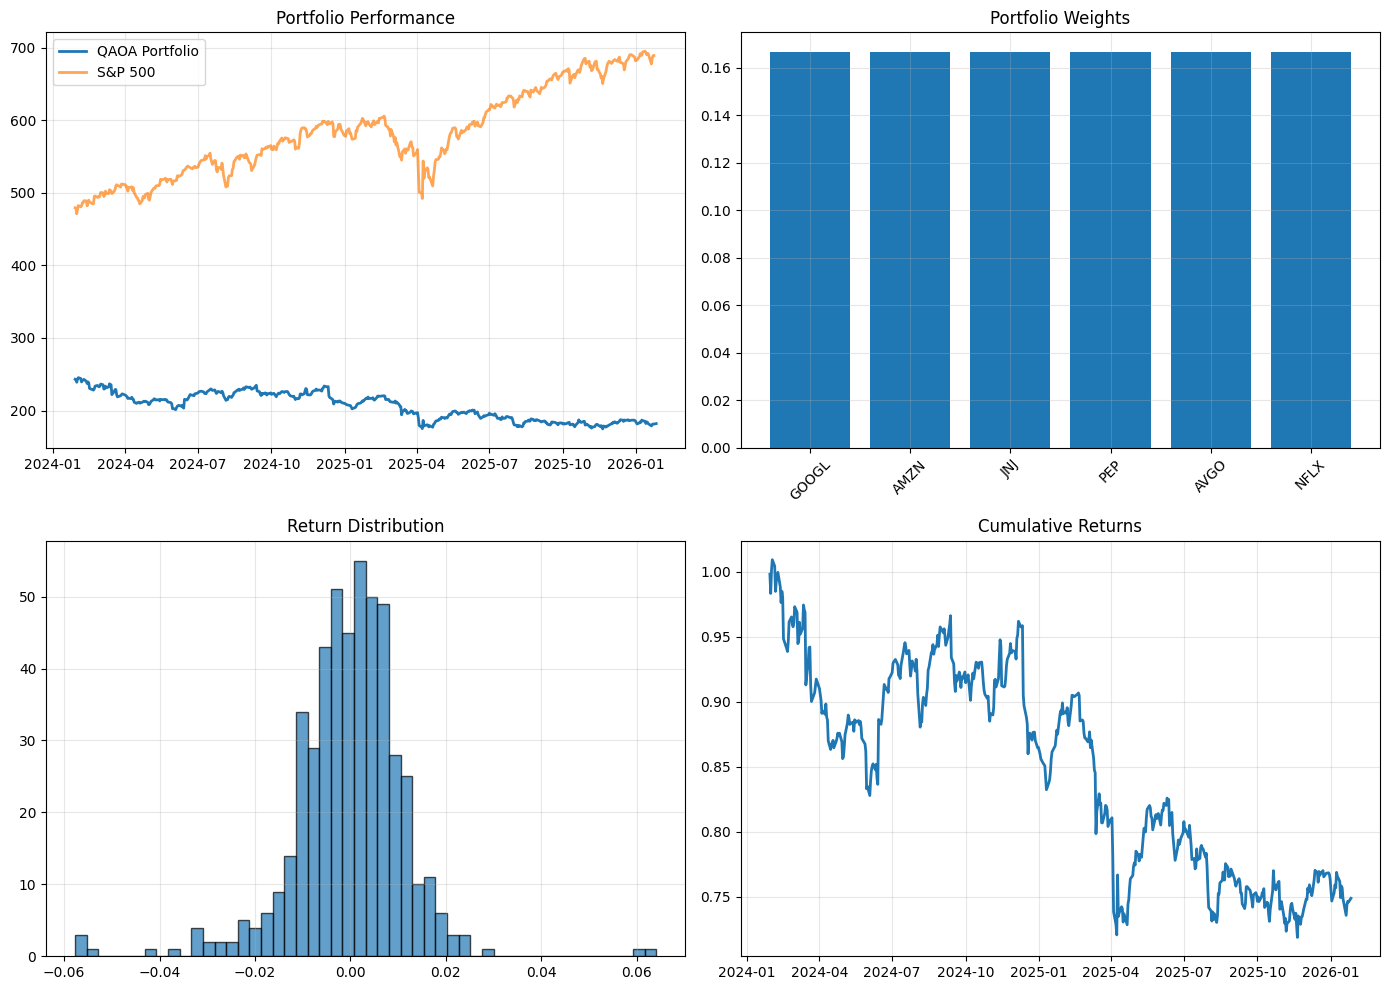

In [4]:
result5 = run_qaoa_optimization(
        tickers=stocks,
        max_assets=6,
        risk_coef=0.5,
        years=2,
        qaoa_layers=1  # Increase for better results (slower)
    )

In [ ]:
result5 = run_qaoa_optimization(
        tickers=stocks,
        max_assets=6,
        risk_coef=0.5,
        years=2,
        qaoa_layers=1  # Increase for better results (slower)
    )

In [2]:
stocks2 = [
        'AAPL', 'MSFT', 'NVDA', 'AVGO','JPM', 'V', 'MA', 'UNH', 'JNJ', 'LLY', 'AMZN', 'TSLA', 'HD', 'WMT', 'PG', 'KO', 'GOOGL', 'META', 'XOM', 'CVX', 'COP', 'UNP', 'CAT', 'BA', 'NEE', 'DUK', 'PLD', 'AMT'
    ]

IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)

[1/8] Downloading data...
[2/8] Calculating returns and covariance...
[3/8] Building QUBO...
[4/8] Converting to Ising Hamiltonian...
[5/8] Running QAOA optimization...
Running QAOA with p=1 layers...
Optimization converged: True
Final energy: -15.2529
[6/8] Decoding solution...

Raw solution: 28 assets selected
Constraint violated! Applying post-processing...
Final selection: ['AAPL', 'MSFT', 'NVDA', 'AVGO', 'JPM', 'V', 'MA', 'UNH', 'JNJ', 'LLY']
[7/8] Allocating weights...

RESULTS

Selected Stocks & Weights:
  AAPL: 0.00%
  MSFT: 0.00%
  NVDA: 0.00%
  AVGO: 8.98%
  JPM: 0.00%
  V: 17.99%
  MA: 0.00%
  UNH: 0.00%
  JNJ: 51.33%
  LLY: 21.70%
[8/8] Calculating metrics...

Portfolio Metrics:
  Expected Return: 31.42%
  Volatility: 13.99%
  Sharpe Ratio: 2.25


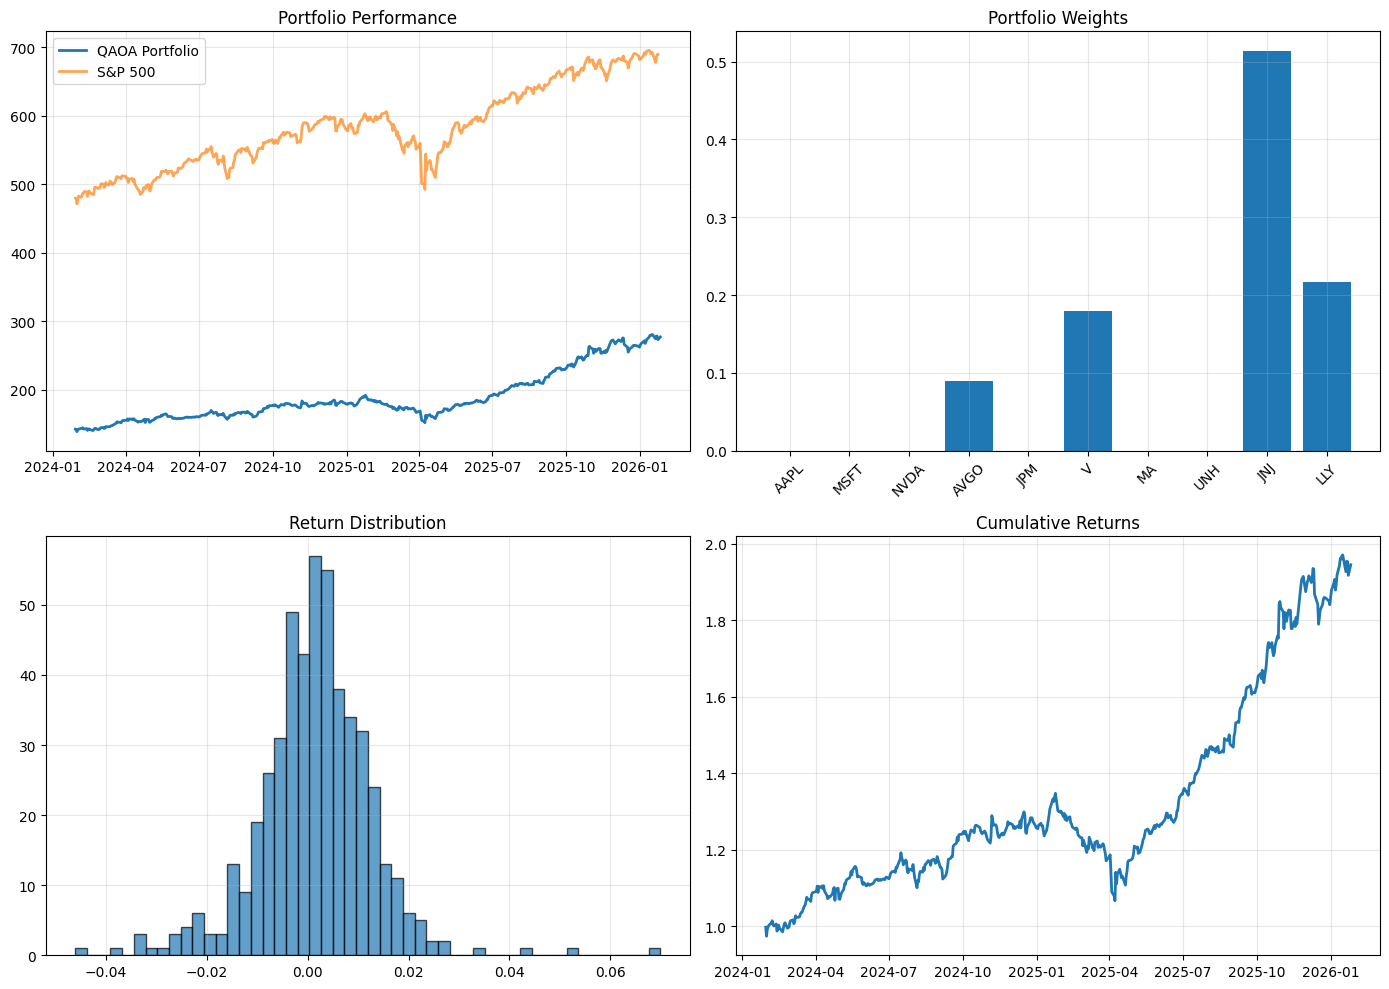

In [3]:
result6 = run_qaoa_optimization(
        tickers=stocks2,
        max_assets=10,
        risk_coef=0.55,
        years=2,
        qaoa_layers=1  # Increase for better results (slower)
    )

### updated with rolling window

In [1]:
stocks = [
        'AAPL', 'MSFT', 'NVDA', 'AVGO','JPM', 'V', 'MA', 'UNH', 'JNJ', 'LLY', 'AMZN', 'TSLA', 'HD', 'WMT', 'PG', 'KO', 'GOOGL', 'META', 'XOM', 'CVX', 'COP', 'UNP', 'CAT', 'BA', 'NEE', 'DUK', 'PLD', 'AMT'
    ]

In [2]:
"""
IBM Quantum QAOA Portfolio Optimization - Enhanced Version
Features:
- Rolling window rebalancing
- Initial capital allocation
- Performance tracking
Uses local Qiskit simulator for quantum optimization
"""

import numpy as np
import pandas as pd
import yfinance as yf
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter
from qiskit_aer.primitives import Sampler

# ============================================================================
# DATA ACQUISITION
# ============================================================================

def get_stock_data(tickers, years=2):
    end = datetime.now()
    start = end - timedelta(days=years*365)

    data = yf.download(
        tickers,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )

    if isinstance(data.columns, pd.MultiIndex):
        prices = data['Close']
    else:
        prices = data[['Close']]

    return prices.dropna()

def calculate_returns(price_data):
    """Calculate returns and covariance"""
    returns = price_data.pct_change().dropna()
    mean_returns = returns.mean()
    cov_matrix = returns.cov()
    return returns, mean_returns, cov_matrix

# ============================================================================
# STEP R1: FORMULATE AS QUBO
# ============================================================================

def build_qubo(mean_returns, cov_matrix, max_assets, risk_coef, penalty=10):
    """
    Build QUBO matrix for portfolio optimization
    
    Minimize: risk_coef * x^T Cov x - returns^T x + penalty * (sum(x) - B)^2
    """
    n = len(mean_returns)
    Q = np.zeros((n, n))
    
    # Risk term: quadratic covariance
    Q += risk_coef * cov_matrix.values
    
    # Return term: linear (on diagonal for QUBO format)
    for i in range(n):
        Q[i, i] -= mean_returns.iloc[i]
    
    # Cardinality constraint penalty: (sum(x) - B)^2
    # Expands to: sum(x_i^2) + 2*sum(x_i*x_j) - 2*B*sum(x_i) + B^2
    for i in range(n):
        Q[i, i] += penalty * (1 - 2 * max_assets)
        for j in range(i + 1, n):
            Q[i, j] += penalty
            Q[j, i] += penalty
    
    return Q

# ============================================================================
# STEP R2: CONVERT TO ISING HAMILTONIAN
# ============================================================================

def qubo_to_ising(Q):
    """
    Convert QUBO to Ising Hamiltonian
    x ∈ {0,1} → s ∈ {-1,+1}
    Transformation: x = (s + 1) / 2
    """
    n = Q.shape[0]
    
    # Initialize Ising parameters
    h = np.zeros(n)  # Linear terms
    J = np.zeros((n, n))  # Quadratic terms
    offset = 0
    
    # Convert QUBO to Ising
    for i in range(n):
        h[i] = Q[i, i] / 2
        for j in range(n):
            h[i] += Q[i, j] / 4
            offset += Q[i, j] / 4
    
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = Q[i, j] / 4
    
    # Normalize for circuit stability
    max_val = max(np.max(np.abs(h)), np.max(np.abs(J)))
    if max_val > 0:
        h = h / max_val
        J = J / max_val
    
    return h, J, offset

# ============================================================================
# STEP R3: BUILD QAOA CIRCUIT
# ============================================================================

def build_qaoa_circuit(h, J, p=1):
    """
    Build QAOA circuit with p layers
    
    Args:
        h: Linear Ising coefficients
        J: Quadratic Ising coefficients
        p: Number of QAOA layers
    """
    n = len(h)
    qc = QuantumCircuit(n)
    
    # Parameters
    gamma = [Parameter(f'γ_{i}') for i in range(p)]
    beta = [Parameter(f'β_{i}') for i in range(p)]
    
    # Initial state: uniform superposition
    qc.h(range(n))
    
    # QAOA layers
    for layer in range(p):
        # Cost Hamiltonian: exp(-i * gamma * H_C)
        # Apply ZZ gates for coupling terms
        for i in range(n):
            for j in range(i + 1, n):
                if J[i, j] != 0:
                    qc.rzz(2 * gamma[layer] * J[i, j], i, j)
        
        # Apply Z gates for linear terms
        for i in range(n):
            if h[i] != 0:
                qc.rz(2 * gamma[layer] * h[i], i)
        
        # Mixer Hamiltonian: exp(-i * beta * H_M)
        for i in range(n):
            qc.rx(2 * beta[layer], i)
    
    # Measure all qubits
    qc.measure_all()
    
    return qc, gamma + beta

# ============================================================================
# STEP R4 & R5: RUN QAOA OPTIMIZATION
# ============================================================================

def evaluate_energy(counts, h, J):
    """Calculate expected energy from measurement counts"""
    energy = 0
    total_shots = sum(counts.values())
    
    for bitstring, count in counts.items():
        # Convert bitstring to spin configuration
        s = np.array([1 if bit == '0' else -1 for bit in bitstring])
        
        # Calculate energy for this configuration
        E = np.dot(h, s) + sum(J[i, j] * s[i] * s[j] 
                               for i in range(len(s)) 
                               for j in range(i + 1, len(s)))
        
        energy += E * (count / total_shots)
    
    return energy

def run_qaoa(h, J, p=1, max_iter=50, verbose=True):
    """
    Run QAOA optimization using local simulator
    
    Args:
        h: Linear Ising coefficients
        J: Quadratic Ising coefficients
        p: Number of QAOA layers
        max_iter: Maximum optimization iterations
        verbose: Print progress
    """
    if verbose:
        print(f"Running QAOA with p={p} layers...")
    
    # Build circuit
    qc, params = build_qaoa_circuit(h, J, p)
    
    # Use local simulator (no API key needed)
    backend = AerSimulator()
    
    # Objective function
    def objective(theta):
        bound_circuit = qc.assign_parameters(dict(zip(params, theta)), inplace=False)
        job = backend.run(bound_circuit, shots=1024)
        counts = job.result().get_counts()
        return evaluate_energy(counts, h, J)
    
    # Initial parameters
    initial_theta = np.random.uniform(0, 2*np.pi, len(params))
    
    # Optimize
    result = minimize(objective, initial_theta, method='COBYLA', 
                     options={'maxiter': max_iter})
    
    if verbose:
        print(f"Optimization converged: {result.success}")
        print(f"Final energy: {result.fun:.4f}")
    
    # Get final measurement
    final_circuit = qc.assign_parameters(dict(zip(params, result.x)), inplace=False)
    job = backend.run(final_circuit, shots=2048)
    counts = job.result().get_counts()
    
    return counts, result.fun

# ============================================================================
# STEP R6 & R7: DECODE SOLUTION
# ============================================================================

def decode_solution(counts, max_assets, tickers, verbose=True):
    """
    Extract most probable solution and verify constraints
    
    Returns selected stocks
    """
    # Get most frequent bitstring
    best_bitstring = max(counts, key=counts.get)
    
    # Convert to binary selection
    selected = [i for i, bit in enumerate(best_bitstring) if bit == '0']
    
    if verbose:
        print(f"\nRaw solution: {len(selected)} assets selected")
    
    # Step R7: Verify cardinality constraint
    if len(selected) != max_assets:
        if verbose:
            print(f"Constraint violated! Applying post-processing...")
        # Get all candidates sorted by probability
        candidates = []
        for bitstring, count in counts.items():
            selection = [i for i, bit in enumerate(bitstring) if bit == '0']
            if abs(len(selection) - max_assets) <= 2:  # Close to target
                candidates.append((selection, count))
        
        # Pick best valid solution
        for selection, count in sorted(candidates, key=lambda x: x[1], reverse=True):
            if len(selection) == max_assets:
                selected = selection
                if verbose:
                    print(f"Found valid solution with {count} counts")
                break
        else:
            # Force to exact count
            if len(selected) > max_assets:
                selected = selected[:max_assets]
            else:
                # Add random stocks to meet constraint
                remaining = [i for i in range(len(tickers)) if i not in selected]
                selected.extend(remaining[:max_assets - len(selected)])
    
    selected_stocks = [tickers[i] for i in selected]
    if verbose:
        print(f"Final selection: {selected_stocks}")
    
    return selected, selected_stocks

# ============================================================================
# STEP R8: CLASSICAL WEIGHT ALLOCATION
# ============================================================================

def allocate_weights(selected_indices, mean_returns, cov_matrix, method='sharpe'):
    """
    Classical optimization for portfolio weights
    
    Args:
        method: 'sharpe' (maximize Sharpe ratio) or 'min_var' (minimum variance)
    """
    selected_returns = mean_returns.iloc[selected_indices]
    selected_cov = cov_matrix.iloc[selected_indices, selected_indices]
    n = len(selected_indices)
    
    if method == 'sharpe':
        # Maximize Sharpe ratio (return/risk)
        def negative_sharpe(w):
            port_return = w @ selected_returns
            port_vol = np.sqrt(w @ selected_cov @ w)
            if port_vol == 0:
                return 1e10
            return -port_return / port_vol  # Negative because we minimize
    
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0, 1) for _ in range(n)]
        initial = np.ones(n) / n
        
        result = minimize(negative_sharpe, initial, method='SLSQP', 
                         bounds=bounds, constraints=constraints)
    
    elif method == 'min_var':
        # Minimum variance
        def portfolio_variance(w):
            return w @ selected_cov @ w
        
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0, 1) for _ in range(n)]
        initial = np.ones(n) / n
        
        result = minimize(portfolio_variance, initial, method='SLSQP', 
                         bounds=bounds, constraints=constraints)
    
    else:
        raise ValueError("method must be 'sharpe' or 'min_var'")
    
    return result.x

# ============================================================================
# PERFORMANCE METRICS
# ============================================================================

def calculate_metrics(weights, mean_returns, cov_matrix, risk_free_rate=0.0):
    port_return = weights @ mean_returns
    port_vol = np.sqrt(weights @ cov_matrix @ weights)

    excess_return = port_return - risk_free_rate/252
    sharpe = excess_return / port_vol if port_vol > 0 else 0

    return {
        'return': port_return * 252,
        'volatility': port_vol * np.sqrt(252),
        'sharpe': sharpe * np.sqrt(252)
    }


# ============================================================================
# NEW: ROLLING WINDOW FUNCTIONALITY
# ============================================================================

def rolling_window_optimization(
    tickers,
    initial_capital=100000,
    max_assets=6,
    risk_coef=0.5,
    window_size=252,  # Trading days for lookback
    rebalance_freq=63,  # Rebalance every quarter (63 trading days)
    total_periods=504,  # 2 years forward
    qaoa_layers=1,
    weight_method='sharpe'
):
    """
    Run portfolio optimization with rolling window rebalancing
    
    Args:
        tickers: List of stock tickers
        initial_capital: Starting capital ($)
        max_assets: Maximum number of stocks in portfolio
        risk_coef: Risk coefficient in QUBO
        window_size: Lookback period in trading days
        rebalance_freq: How often to rebalance (trading days)
        total_periods: Total forward period to simulate
        qaoa_layers: QAOA depth
        weight_method: 'sharpe' or 'min_var'
    
    Returns:
        Dictionary with portfolio history and performance
    """
    print("="*70)
    print("ROLLING WINDOW QAOA PORTFOLIO OPTIMIZATION")
    print("="*70)
    print(f"\nInitial Capital: ${initial_capital:,.2f}")
    print(f"Window Size: {window_size} days")
    print(f"Rebalance Frequency: {rebalance_freq} days")
    print(f"Max Assets: {max_assets}")
    print("")
    
    # Download extended data
    end_date = datetime.now()
    start_date = end_date - timedelta(days=int((window_size + total_periods) * 1.5))
    
    print("Downloading price data...")
    price_data = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )
    
    if isinstance(price_data.columns, pd.MultiIndex):
        prices = price_data['Close']
    else:
        prices = price_data[['Close']]
    
    prices = prices.dropna()
    
    # Initialize tracking
    portfolio_history = []
    rebalance_dates = []
    holdings_history = []
    
    # Starting point
    start_idx = window_size
    current_capital = initial_capital
    current_holdings = {}  # {ticker: shares}
    
    rebalance_count = 0
    
    # Rolling window loop
    while start_idx + rebalance_freq < len(prices):
        rebalance_date = prices.index[start_idx]
        rebalance_dates.append(rebalance_date)
        rebalance_count += 1
        
        print(f"\n{'='*70}")
        print(f"REBALANCE #{rebalance_count} - {rebalance_date.strftime('%Y-%m-%d')}")
        print(f"{'='*70}")
        
        # Get lookback window
        lookback_prices = prices.iloc[start_idx - window_size:start_idx]
        
        # Calculate returns and covariance on lookback window
        returns, mean_returns, cov_matrix = calculate_returns(lookback_prices)
        
        # Run QAOA optimization
        print("\n[1/4] Building QUBO...")
        Q = build_qubo(mean_returns, cov_matrix, max_assets, risk_coef)
        
        print("[2/4] Converting to Ising & Running QAOA...")
        h, J, offset = qubo_to_ising(Q)
        counts, energy = run_qaoa(h, J, p=qaoa_layers, verbose=False)
        
        print("[3/4] Decoding solution...")
        selected_idx, selected_stocks = decode_solution(
            counts, max_assets, tickers, verbose=False
        )
        
        print("[4/4] Allocating weights...")
        weights = allocate_weights(selected_idx, mean_returns, cov_matrix, method=weight_method)
        
        # Get current prices at rebalance
        current_prices = prices.iloc[start_idx]
        
        # Liquidate old holdings
        if current_holdings:
            liquidation_value = sum(
                current_holdings[ticker] * current_prices[ticker]
                for ticker in current_holdings
                if ticker in current_prices.index
            )
            current_capital = liquidation_value
            print(f"\nLiquidated portfolio value: ${current_capital:,.2f}")
        
        # Calculate new holdings
        new_holdings = {}
        for stock, weight in zip(selected_stocks, weights):
            allocation = current_capital * weight
            shares = allocation / current_prices[stock]
            new_holdings[stock] = shares
        
        current_holdings = new_holdings
        
        print(f"\nNew Portfolio Allocation:")
        for stock, shares in current_holdings.items():
            value = shares * current_prices[stock]
            print(f"  {stock}: {shares:.2f} shares (${value:,.2f})")
        
        holdings_history.append({
            'date': rebalance_date,
            'holdings': current_holdings.copy(),
            'stocks': selected_stocks,
            'weights': weights.copy()
        })
        
        # Track portfolio value daily until next rebalance
        end_idx = min(start_idx + rebalance_freq, len(prices))
        for i in range(start_idx, end_idx):
            daily_prices = prices.iloc[i]
            portfolio_value = sum(
                current_holdings[ticker] * daily_prices[ticker]
                for ticker in current_holdings
                if ticker in daily_prices.index
            )
            portfolio_history.append({
                'date': prices.index[i],
                'value': portfolio_value,
                'holdings': current_holdings.copy()
            })
        
        # Move to next rebalance
        start_idx += rebalance_freq
        
        if start_idx + rebalance_freq >= len(prices):
            print(f"\nReached end of available data.")
            break
    
    # Convert to DataFrame
    portfolio_df = pd.DataFrame(portfolio_history)
    portfolio_df.set_index('date', inplace=True)
    
    # Calculate final metrics
    final_value = portfolio_df['value'].iloc[-1]
    total_return = (final_value - initial_capital) / initial_capital
    
    returns_series = portfolio_df['value'].pct_change().dropna()
    annual_return = returns_series.mean() * 252
    annual_vol = returns_series.std() * np.sqrt(252)
    sharpe_ratio = annual_return / annual_vol if annual_vol > 0 else 0
    
    max_drawdown = (portfolio_df['value'] / portfolio_df['value'].cummax() - 1).min()
    
    print("\n" + "="*70)
    print("FINAL RESULTS")
    print("="*70)
    print(f"\nInitial Capital: ${initial_capital:,.2f}")
    print(f"Final Value: ${final_value:,.2f}")
    print(f"Total Return: {total_return:.2%}")
    print(f"Annual Return: {annual_return:.2%}")
    print(f"Annual Volatility: {annual_vol:.2%}")
    print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
    print(f"Max Drawdown: {max_drawdown:.2%}")
    print(f"Number of Rebalances: {rebalance_count}")
    
    return {
        'portfolio_history': portfolio_df,
        'holdings_history': holdings_history,
        'rebalance_dates': rebalance_dates,
        'initial_capital': initial_capital,
        'final_value': final_value,
        'total_return': total_return,
        'annual_return': annual_return,
        'annual_volatility': annual_vol,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown
    }

# ============================================================================
# VISUALIZATION FOR ROLLING WINDOW
# ============================================================================

def plot_rolling_results(result, benchmark_ticker='SPY'):
    """
    Plot results from rolling window optimization
    
    Args:
        result: Output from rolling_window_optimization
        benchmark_ticker: Ticker for benchmark comparison
    """
    portfolio_df = result['portfolio_history']
    
    # Download benchmark data
    benchmark_data = yf.download(
        benchmark_ticker,
        start=portfolio_df.index[0],
        end=portfolio_df.index[-1],
        auto_adjust=True,
        progress=False
    )['Close']
    
    # Normalize to initial capital
    initial_capital = result['initial_capital']
    benchmark_normalized = benchmark_data / benchmark_data.iloc[0] * initial_capital
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # Portfolio value over time
    axes[0, 0].plot(portfolio_df.index, portfolio_df['value'], 
                    label='QAOA Portfolio', linewidth=2, color='#2E86AB')
    axes[0, 0].plot(benchmark_normalized.index, benchmark_normalized.values,
                    label=f'{benchmark_ticker} Benchmark', linewidth=2, 
                    alpha=0.7, color='#A23B72')
    
    # Mark rebalance dates
    for date in result['rebalance_dates']:
        axes[0, 0].axvline(date, color='gray', alpha=0.3, linestyle='--', linewidth=0.8)
    
    axes[0, 0].set_title('Portfolio Value Over Time', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Date')
    axes[0, 0].set_ylabel('Value ($)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1000:.0f}K'))
    
    # Cumulative returns
    portfolio_returns = portfolio_df['value'] / result['initial_capital'] - 1
    benchmark_returns = benchmark_normalized / result['initial_capital'] - 1
    
    axes[0, 1].plot(portfolio_returns.index, portfolio_returns.values * 100,
                    label='QAOA Portfolio', linewidth=2, color='#2E86AB')
    axes[0, 1].plot(benchmark_returns.index, benchmark_returns.values * 100,
                    label=f'{benchmark_ticker} Benchmark', linewidth=2,
                    alpha=0.7, color='#A23B72')
    axes[0, 1].axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)
    axes[0, 1].set_title('Cumulative Returns', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Return (%)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Drawdown
    running_max = portfolio_df['value'].cummax()
    drawdown = (portfolio_df['value'] - running_max) / running_max * 100
    
    axes[1, 0].fill_between(drawdown.index, drawdown.values, 0, 
                            alpha=0.3, color='#F18F01')
    axes[1, 0].plot(drawdown.index, drawdown.values, linewidth=2, color='#F18F01')
    axes[1, 0].set_title('Drawdown', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Date')
    axes[1, 0].set_ylabel('Drawdown (%)')
    axes[1, 0].grid(True, alpha=0.3)
    
    # Rolling Sharpe Ratio (60-day window)
    returns_series = portfolio_df['value'].pct_change()
    rolling_sharpe = (returns_series.rolling(60).mean() / 
                     returns_series.rolling(60).std() * np.sqrt(252))
    
    axes[1, 1].plot(rolling_sharpe.index, rolling_sharpe.values, 
                    linewidth=2, color='#06A77D')
    axes[1, 1].axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)
    axes[1, 1].set_title('Rolling Sharpe Ratio (60-day)', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Date')
    axes[1, 1].set_ylabel('Sharpe Ratio')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Additional plot: Holdings over time
    fig2, ax = plt.subplots(figsize=(14, 6))
    
    # Create a timeline of holdings
    all_stocks = set()
    for entry in result['holdings_history']:
        all_stocks.update(entry['stocks'])
    
    all_stocks = sorted(list(all_stocks))
    
    holdings_timeline = []
    for entry in result['holdings_history']:
        row = {stock: (stock in entry['stocks']) for stock in all_stocks}
        row['date'] = entry['date']
        holdings_timeline.append(row)
    
    holdings_df = pd.DataFrame(holdings_timeline)
    holdings_df.set_index('date', inplace=True)
    
    # Plot as heatmap-style
    y_pos = np.arange(len(all_stocks))
    for i, stock in enumerate(all_stocks):
        dates = holdings_df.index[holdings_df[stock] == True]
        for date in dates:
            ax.scatter(date, i, marker='s', s=100, color='#2E86AB', alpha=0.7)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(all_stocks)
    ax.set_xlabel('Date')
    ax.set_title('Portfolio Holdings Timeline', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()

def plot_results(portfolio_value, benchmark_value, selected_stocks, weights):
    """Generate performance plots for single optimization"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    axes[0, 0].plot(portfolio_value.index, portfolio_value.values, label='QAOA Portfolio', linewidth=2)
    axes[0, 0].plot(benchmark_value.index, benchmark_value.values, label='S&P 500', linewidth=2, alpha=0.7)
    axes[0, 0].set_title('Portfolio Performance')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].bar(selected_stocks, weights)
    axes[0, 1].set_title('Portfolio Weights')
    axes[0, 1].tick_params(axis='x', rotation=45)
    axes[0, 1].grid(True, alpha=0.3)
    
    returns = portfolio_value.pct_change().dropna()
    axes[1, 0].hist(returns, bins=50, alpha=0.7, edgecolor='black')
    axes[1, 0].set_title('Return Distribution')
    axes[1, 0].grid(True, alpha=0.3)
    
    cum_returns = (1 + portfolio_value.pct_change()).cumprod()
    axes[1, 1].plot(cum_returns.index, cum_returns.values, linewidth=2)
    axes[1, 1].set_title('Cumulative Returns')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# ============================================================================
# MAIN EXECUTION - SINGLE OPTIMIZATION
# ============================================================================

def run_qaoa_optimization(tickers, max_assets=6, risk_coef=0.5, years=2, qaoa_layers=1):
    """Run complete QAOA optimization pipeline"""
    
    print("="*70)
    print("IBM QAOA PORTFOLIO OPTIMIZATION (LOCAL SIMULATOR)")
    print("="*70)
    
    print("\n[1/8] Downloading data...")
    price_data = get_stock_data(tickers, years)
    
    print("[2/8] Calculating returns and covariance...")
    returns, mean_returns, cov_matrix = calculate_returns(price_data)
    
    print("[3/8] Building QUBO...")
    Q = build_qubo(mean_returns, cov_matrix, max_assets, risk_coef)
    
    print("[4/8] Converting to Ising Hamiltonian...")
    h, J, offset = qubo_to_ising(Q)
    
    print("[5/8] Running QAOA optimization...")
    counts, energy = run_qaoa(h, J, p=qaoa_layers)
    
    print("[6/8] Decoding solution...")
    selected_idx, selected_stocks = decode_solution(counts, max_assets, tickers)
    
    print("[7/8] Allocating weights...")
    weights = allocate_weights(selected_idx, mean_returns, cov_matrix)
    
    print("\n" + "="*70)
    print("RESULTS")
    print("="*70)
    print("\nSelected Stocks & Weights:")
    for stock, weight in zip(selected_stocks, weights):
        print(f"  {stock}: {weight:.2%}")
    
    print("[8/8] Calculating metrics...")
    metrics = calculate_metrics(weights, mean_returns.iloc[selected_idx], 
                               cov_matrix.iloc[selected_idx, selected_idx])
    
    print(f"\nPortfolio Metrics:")
    print(f"  Expected Return: {metrics['return']:.2%}")
    print(f"  Volatility: {metrics['volatility']:.2%}")
    print(f"  Sharpe Ratio: {metrics['sharpe']:.2f}")
    
    # Backtest
    selected_prices = price_data.iloc[:, selected_idx]
    portfolio_value = (selected_prices @ weights).dropna()
    
    spy_data = yf.download(
        'SPY',
        start=price_data.index[0],
        end=price_data.index[-1],
        auto_adjust=True,
        progress=False
    )['Close']

    plot_results(portfolio_value, spy_data, selected_stocks, weights)
    
    return {
        'stocks': selected_stocks,
        'weights': weights,
        'metrics': metrics,
        'energy': energy
    }



ROLLING WINDOW OPTIMIZATION
ROLLING WINDOW QAOA PORTFOLIO OPTIMIZATION

Initial Capital: $100,000.00
Window Size: 252 days
Rebalance Frequency: 63 days
Max Assets: 4


REBALANCE #1 - 2024-01-04

[1/4] Building QUBO...
[2/4] Converting to Ising & Running QAOA...
[3/4] Decoding solution...
[4/4] Allocating weights...

New Portfolio Allocation:
  NVDA: 756.83 shares ($36,306.13)
  AVGO: 549.68 shares ($56,385.70)
  JPM: 35.40 shares ($5,813.52)
  V: 5.84 shares ($1,494.65)

REBALANCE #2 - 2024-04-05

[1/4] Building QUBO...
[2/4] Converting to Ising & Running QAOA...
[3/4] Decoding solution...
[4/4] Allocating weights...

Liquidated portfolio value: $147,210.27

New Portfolio Allocation:
  MSFT: 0.00 shares ($0.00)
  PG: 630.33 shares ($93,460.84)
  CVX: 359.10 shares ($53,749.43)
  CAT: 0.00 shares ($0.00)

REBALANCE #3 - 2024-07-08

[1/4] Building QUBO...
[2/4] Converting to Ising & Running QAOA...
[3/4] Decoding solution...
[4/4] Allocating weights...

Liquidated portfolio value: $152

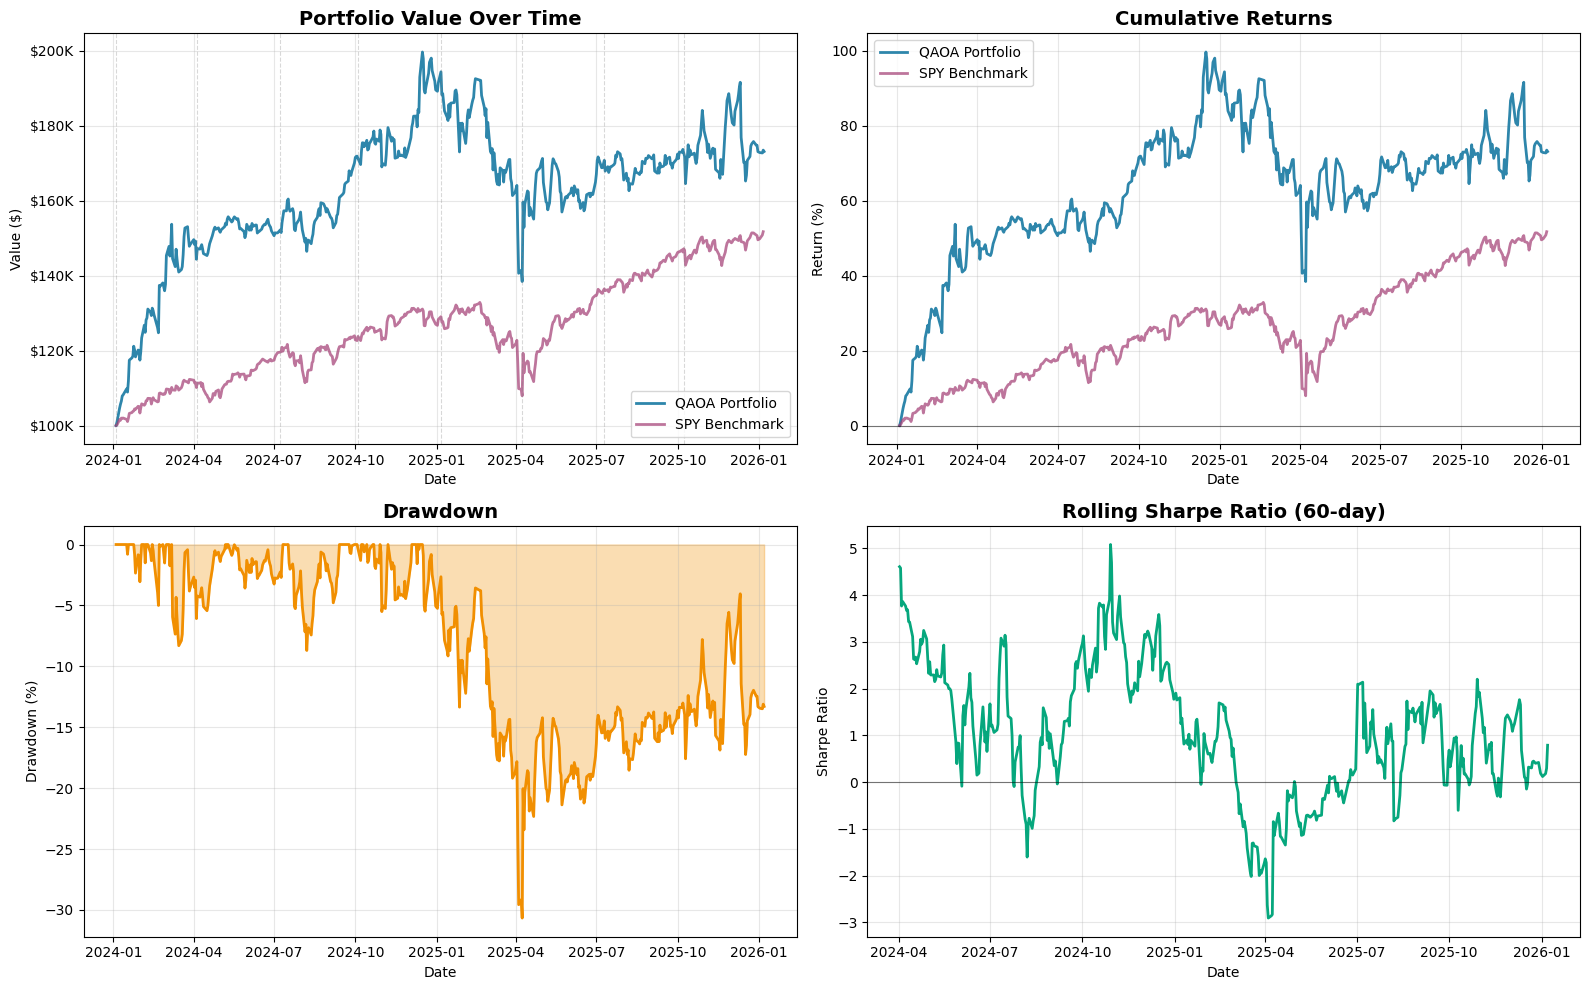

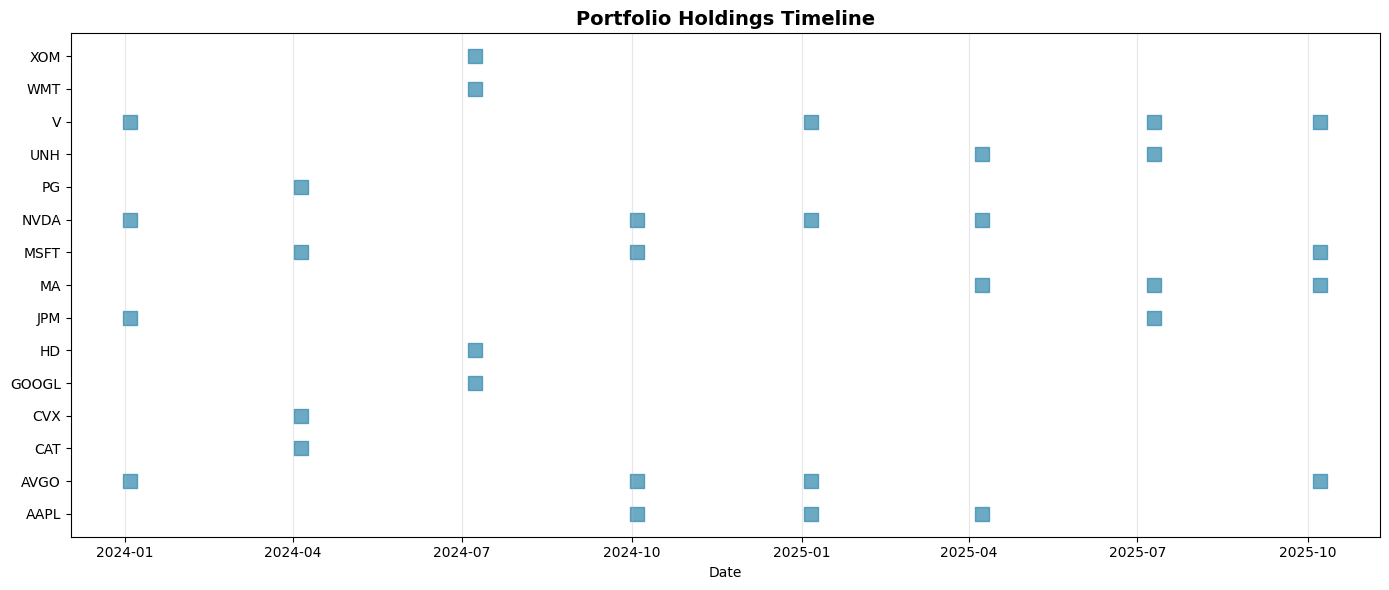

In [3]:
print("\n\n" + "="*70)
print("ROLLING WINDOW OPTIMIZATION")
print("="*70)
    
result_rolling = rolling_window_optimization(
    tickers=stocks,
    initial_capital=100000,  # $100,000 starting capital
    max_assets=4,
    risk_coef=0.5,
    window_size=252,  # 1 year lookback
    rebalance_freq=63,  # Quarterly rebalancing
    total_periods=504,  # 2 years forward
    qaoa_layers=1,
    weight_method='sharpe'
    )

plot_rolling_results(result_rolling, benchmark_ticker='SPY')